# R² before / after the subject-specific design matrices

- **Old**: `prf` folder. prfpy fit, common design (bars A for everybody), z-score.
- **New**: `prfmodel` folder. prfmodel v2 fit, subject-specific designs (B for sub-14 and sub-17, B for sub-05 RE run-01, reconstructed sequences for sub-16), psc.

R² does not depend on the normalization (z-score or psc: linear scaling per vertex).

Tasks:
- full concatenation: `BarsBarsRingsWedges`;
- bars only: `BarsBars`;
- `RingsWedges` as reference: its design did not change, so its gain measures the change of fitting code only.

Subjects whose design changed: sub-05, sub-14, sub-16, sub-17. Data: `*_prf-css_deriv.tsv` (one row per vertex of the ROIs).

In [1]:
# General imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define parameters
main_dir = '/Users/uriel/disks/meso_shared/amblyo7T_prf/'
pp_dir = os.path.join(main_dir, 'derivatives/pp_data/')
fig_dir = '/Users/uriel/Desktop/fig_od/'
subjects = ['sub-{:02d}'.format(i) for i in range(1, 22) if i not in [7, 15]]
changed = ['sub-05', 'sub-14', 'sub-16', 'sub-17']
rois = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
tasks = {'BarsBarsRingsWedges': 'full concatenation', 'BarsBars': 'bars only', 'RingsWedges': 'rings + wedges (reference)'}
versions = {'old (prf, prfpy, design A)': ('prf', 'z-score'),
            'new (prfmodel, subject designs)': ('prfmodel', 'psc')}
rsq_th = 0.3

In [2]:
# Load R2 of every vertex
def tsv_fn(subject, folder, norm, task):
    return os.path.join(pp_dir, subject, 'fsnative', folder, 'tsv',
                        '{}_task-{}_fmriprep_dct_{}_concat_rois-group-mmp_prf-css_deriv.tsv'.format(subject, task, norm))

rows, missing = [], []
for subject in subjects:
    for task in tasks:
        for eye in ['LeftEye', 'RightEye']:
            for version, (folder, norm) in versions.items():
                fn = tsv_fn(subject, folder, norm, task + eye)
                if not os.path.exists(fn):
                    missing.append(fn)
                    continue
                df = pd.read_csv(fn, sep='\t', usecols=['prf_rsq', 'roi'])
                for roi in rois:
                    r2 = df.loc[df['roi'] == roi, 'prf_rsq'].values
                    if len(r2) == 0:
                        continue
                    rows.append({'subject': subject, 'task': task, 'eye': eye, 'version': version, 'roi': roi,
                                 'median_r2': np.nanmedian(r2), 'frac_above_th': np.nanmean(r2 > rsq_th), 'n_vert': len(r2)})
    print(subject, 'loaded', flush=True)
r2 = pd.DataFrame(rows)
r2['design changed'] = r2['subject'].isin(changed)
print('{} missing files'.format(len(missing)))
for fn in missing[:10]:
    print('  ', fn)

sub-01 loaded
sub-02 loaded
sub-03 loaded
sub-04 loaded
sub-05 loaded
sub-06 loaded
sub-08 loaded
sub-09 loaded
sub-10 loaded
sub-11 loaded
sub-12 loaded
sub-13 loaded
sub-14 loaded
sub-16 loaded
sub-17 loaded
sub-18 loaded
sub-19 loaded
sub-20 loaded
sub-21 loaded
0 missing files


In [3]:
# Median R2 per subject (mean of the two eyes), old vs new
old_v, new_v = list(versions)
summ = r2.groupby(['subject', 'design changed', 'task', 'roi', 'version'])[['median_r2', 'frac_above_th']].mean().reset_index()
wide = summ.pivot_table(index=['subject', 'design changed', 'task', 'roi'], columns='version',
                        values=['median_r2', 'frac_above_th']).reset_index()
wide.columns = [' '.join([c for c in col if c]).strip() for col in wide.columns]
wide['gain median_r2'] = wide['median_r2 ' + new_v] - wide['median_r2 ' + old_v]
wide['ratio median_r2'] = wide['median_r2 ' + new_v] / wide['median_r2 ' + old_v]

table = wide[wide['roi'].isin(['V1', 'V2', 'V3'])].groupby(['task', 'design changed'])[['gain median_r2', 'ratio median_r2']].median()
print('Median over subjects and V1-V3 (gain = new - old, ratio = new / old):')
print(table.round(3).to_string())

Median over subjects and V1-V3 (gain = new - old, ratio = new / old):
                                    gain median_r2  ratio median_r2
task                design changed                                 
BarsBars            False                    0.004            1.061
                    True                     0.044            1.836
BarsBarsRingsWedges False                    0.000            1.012
                    True                     0.032            1.498
RingsWedges         False                   -0.008            0.901
                    True                    -0.001            0.996


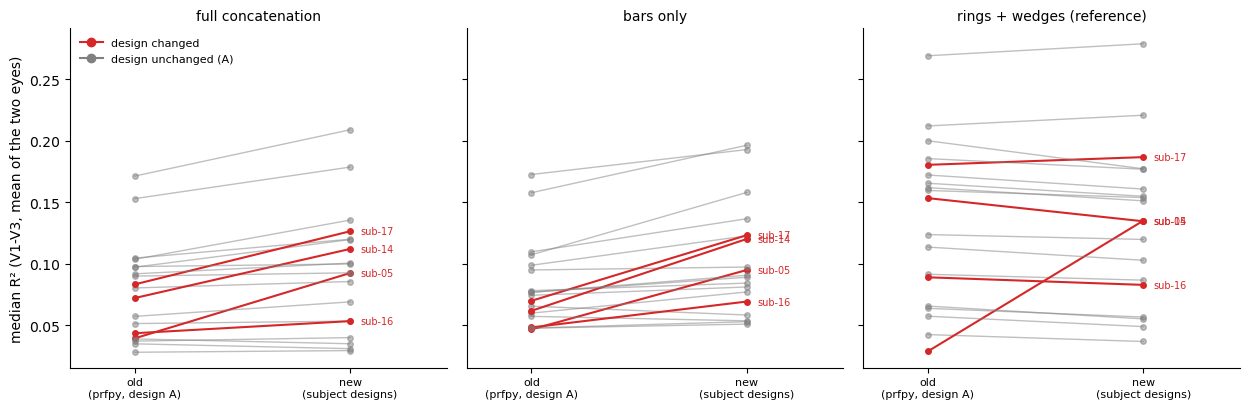

In [4]:
# Figure 1: median R2 old vs new per subject, V1-V3 pooled
v13 = wide[wide['roi'].isin(['V1', 'V2', 'V3'])].groupby(['subject', 'design changed', 'task']).mean(numeric_only=True).reset_index()
fig, axes = plt.subplots(1, len(tasks), figsize=(4.2 * len(tasks), 4.2), sharey=True)
for ax, (task, title) in zip(axes, tasks.items()):
    d = v13[v13['task'] == task]
    for _, row in d.iterrows():
        col = 'tab:red' if row['design changed'] else 'grey'
        ax.plot([0, 1], [row['median_r2 ' + old_v], row['median_r2 ' + new_v]], '-o', color=col,
                alpha=1 if row['design changed'] else 0.5, lw=1.5 if row['design changed'] else 1, ms=4)
        if row['design changed']:
            ax.text(1.05, row['median_r2 ' + new_v], row['subject'], color=col, fontsize=7, va='center')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['old\n(prfpy, design A)', 'new\n(subject designs)'], fontsize=8)
    ax.set_xlim(-0.3, 1.45)
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('median R² (V1-V3, mean of the two eyes)')
axes[0].plot([], [], '-o', color='tab:red', label='design changed')
axes[0].plot([], [], '-o', color='grey', label='design unchanged (A)')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, 'r2_old_vs_new_V1-V3.pdf'), bbox_inches='tight')
plt.show()

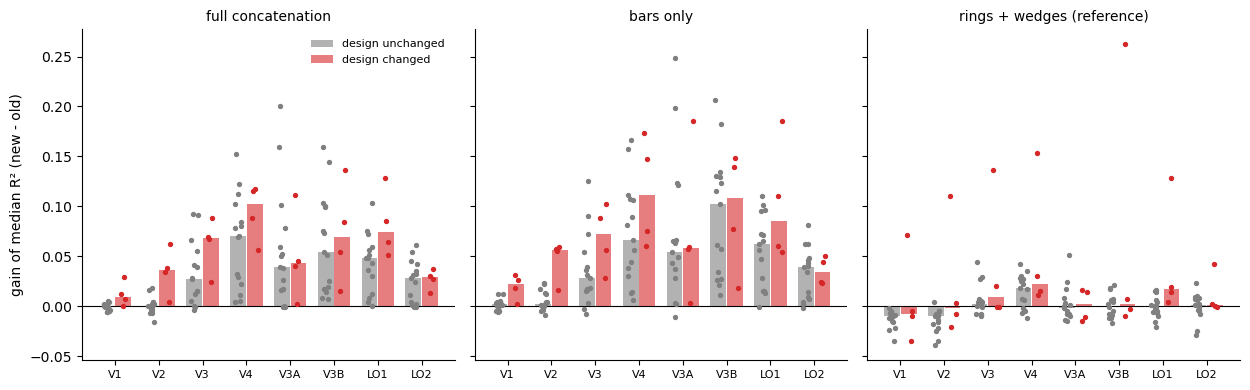

In [5]:
# Figure 2: gain of median R2 per ROI, design changed vs unchanged
fig, axes = plt.subplots(1, len(tasks), figsize=(4.2 * len(tasks), 4), sharey=True)
x = np.arange(len(rois))
for ax, (task, title) in zip(axes, tasks.items()):
    d = wide[wide['task'] == task]
    for k, (flag, col, lab) in enumerate([(False, 'grey', 'design unchanged'), (True, 'tab:red', 'design changed')]):
        dd = d[d['design changed'] == flag]
        med = [dd.loc[dd['roi'] == roi, 'gain median_r2'].median() for roi in rois]
        ax.bar(x + (k - 0.5) * 0.38, med, width=0.36, color=col, alpha=0.6, label=lab)
        for i, roi in enumerate(rois):
            vals = dd.loc[dd['roi'] == roi, 'gain median_r2'].values
            ax.scatter(np.full(len(vals), x[i] + (k - 0.5) * 0.38) + np.random.uniform(-0.08, 0.08, len(vals)),
                       vals, s=8, color=col, zorder=3)
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(rois, fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('gain of median R² (new - old)')
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, 'r2_gain_per_roi.pdf'), bbox_inches='tight')
plt.show()

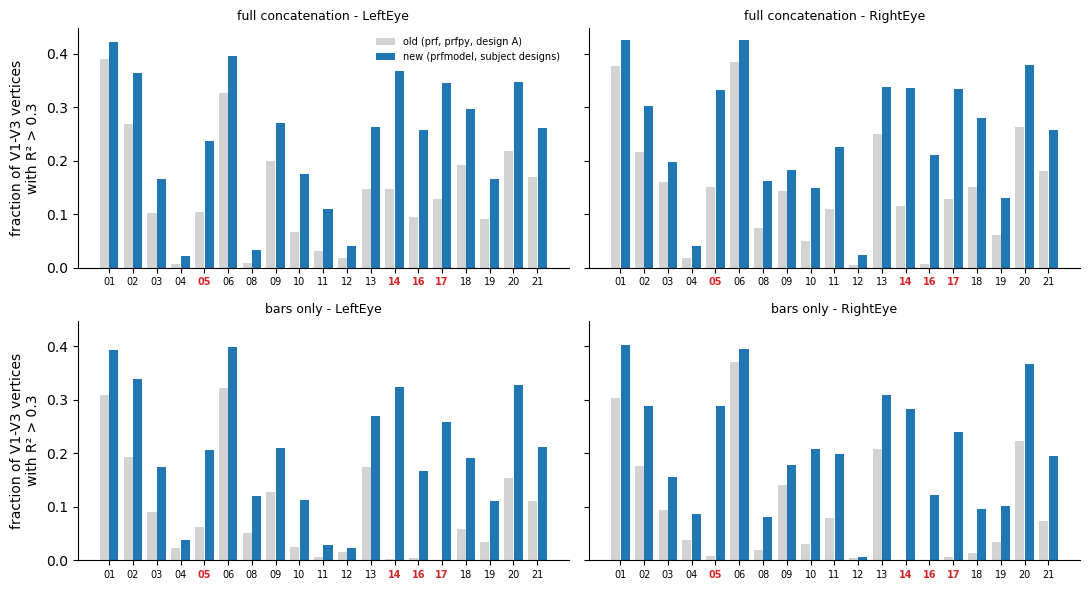

In [6]:
# Figure 3: fraction of vertices above the R2 threshold, per subject and eye (V1-V3)
d = r2[r2['roi'].isin(['V1', 'V2', 'V3'])].groupby(['subject', 'design changed', 'task', 'eye', 'version'])['frac_above_th'].mean().reset_index()
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for i, task in enumerate(['BarsBarsRingsWedges', 'BarsBars']):
    for j, eye in enumerate(['LeftEye', 'RightEye']):
        ax = axes[i, j]
        dd = d[(d['task'] == task) & (d['eye'] == eye)]
        xs = np.arange(len(subjects))
        for k, (version, col) in enumerate([(old_v, 'lightgrey'), (new_v, 'tab:blue')]):
            vals = [dd.loc[(dd['subject'] == s) & (dd['version'] == version), 'frac_above_th'].mean() for s in subjects]
            ax.bar(xs + (k - 0.5) * 0.4, vals, width=0.38, color=col, label=version)
        ax.set_xticks(xs)
        ax.set_xticklabels([s.replace('sub-', '') for s in subjects], fontsize=7)
        for t, s in zip(ax.get_xticklabels(), subjects):
            if s in changed:
                t.set_color('tab:red'); t.set_fontweight('bold')
        ax.set_title('{} - {}'.format(tasks[task], eye), fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].set_ylabel('fraction of V1-V3 vertices\nwith R² > {}'.format(rsq_th))
axes[1, 0].set_ylabel('fraction of V1-V3 vertices\nwith R² > {}'.format(rsq_th))
axes[0, 0].legend(frameon=False, fontsize=7)
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, 'r2_fraction_above_th_per_subject.pdf'), bbox_inches='tight')
plt.show()